##### 1. Precios
**¿Cuánto cuesta la vivienda en España, cuánto ha subido y dónde?**

Para ello usaremos:

- Valor tasado de la vivienda libre (MITMA), vivienda total, 2007-2025.
- Precios en €/m² nominales y en euros constantes de 2025 (IPC base 2025).
- 2026 queda fuera: solo tiene dos trimestres publicados.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# El import de src/ funciona tanto si Jupyter se lanza desde la raíz del
# proyecto como desde notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (  # noqa: E402
    FIGURES_DIR,
    NATIONAL_CODE,
    PROCESSED_DIR,
    PROVINCES,
)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Sin dtype, "04" se convierte en 4 y "00" en 0: el cruce por provincia deja
# de casar. Se lee siempre con el código como texto.
panel = pd.read_csv(
    PROCESSED_DIR / "panel_provincia_anual.csv",
    dtype={"province_code": str},
)

In [2]:
national = (
    panel.loc[(panel["province_code"] == NATIONAL_CODE) & (panel["kind"] == "total")]
    .sort_values("year")
    .reset_index(drop=True)
)

national[["year", "price_nominal_eur_m2", "price_real_eur_m2"]].tail(3)

,year,price_nominal_eur_m2,price_real_eur_m2
16,2023,1809.08,1908.96
17,2024,1913.62,1964.76
18,2025,2127.57,2127.57


##### La figura

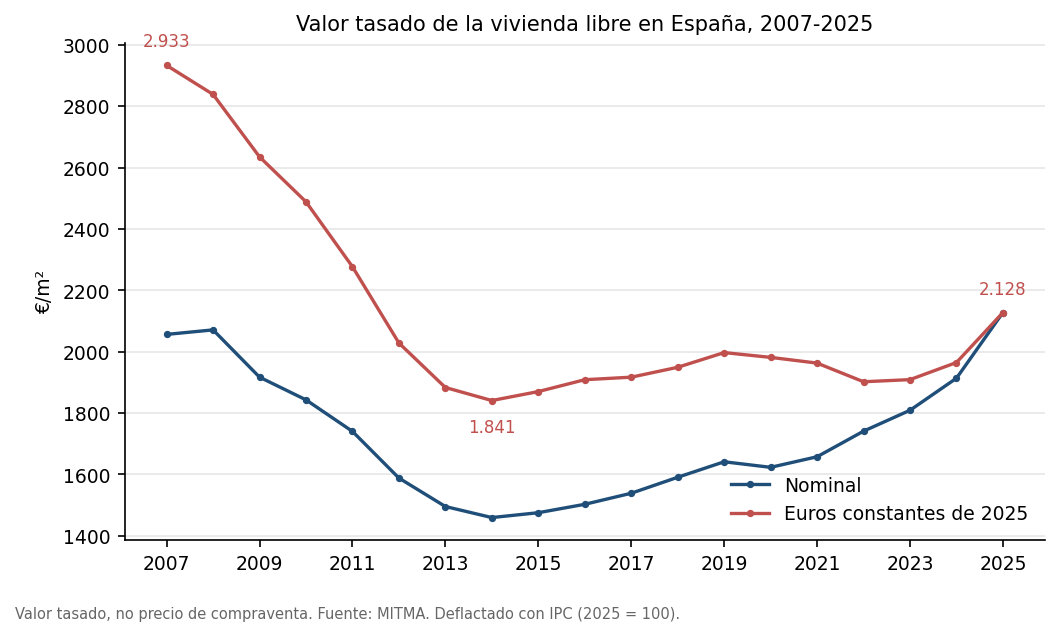

In [3]:
def eur(value):
    return f"{value:,.0f}".replace(",", ".")

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    national["year"], national["price_nominal_eur_m2"],
    marker="o", markersize=2.5, linewidth=1.6,
    color="#1f4e79", label ="Nominal",
    )

ax.plot(
    national["year"], national["price_real_eur_m2"],
    marker="o", markersize=2.5, linewidth=1.6,
    color="#c0504d", label="Euros constantes de 2025",
)

ax.set_title("Valor tasado de la vivienda libre en España, 2007-2025")
ax.set_ylabel("€/m²")
ax.set_xticks(range(2007,2026, 2))
ax.grid(axis="y", color = "0.9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")

peak = national.loc[national["price_real_eur_m2"].idxmax()]
trough = national.loc[national["price_real_eur_m2"].idxmin()]
last = national.iloc[-1]

for row, dy in ((peak, 9), (trough, -15), (last, 9)):
    ax.annotate(
        eur(row["price_real_eur_m2"]),
        (row["year"], row["price_real_eur_m2"]),
        textcoords="offset points", xytext=(0, dy),
        ha="center", fontsize=8, color="#c0504d",
    )

fig.text(
    0.0, -0.04,
    "Valor tasado, no precio de compraventa. Fuente: MITMA. "
    "Deflactado con IPC (2025 = 100).",
    fontsize=7, color="0.4",
)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_nacional_nominal_real.png", bbox_inches="tight")
plt.show()

In [4]:
summary = (
    national.set_index("year")
    .loc[[2007, 2014, 2025], ["price_nominal_eur_m2", "price_real_eur_m2"]]
    .round(0)
    .astype(int)
)
summary.index.name = "año"
summary.columns = ["nominal", "real (2025)"]
display(summary)

print(f"El precio real de 2025 está un {1 - last['price_real_eur_m2'] / peak['price_real_eur_m2']:.1%} "
      "por debajo del máximo de 2007.")
# El máximo nominal de la serie es 2025: para comparar hace falta el pico
# anterior, que fue 2008.
previous = national[national["year"] < last["year"]]
nominal_peak = previous.loc[previous["price_nominal_eur_m2"].idxmax()]

print(f"En nominal, 2025 supera el máximo anterior ({int(nominal_peak['year'])}) en "
      f"{last['price_nominal_eur_m2'] / nominal_peak['price_nominal_eur_m2'] - 1:+.1%}.")

,nominal,real (2025)
año,,
2007,2056,2933
2014,1459,1841
2025,2128,2128


El precio real de 2025 está un 27.5% por debajo del máximo de 2007.
En nominal, 2025 supera el máximo anterior (2008) en +2.7%.


##### Análisis de los resultados

Tenemos que tener en cuenta que estamos hablando de **valor tasado**, es decir, lo
que una sociedad de tasación dice que vale un metro cuadrado. Se parece al precio
real y se mueve con él, pero no es lo mismo.

**Diferencia entre las dos líneas**

Un euro de 2007 y un euro de 2025 no valen lo mismo. Con 2.056 € de 2007 te
comprabas más cosas que con 2.056 € de 2025, porque entre medias los precios de
todo (pan, gasolina, alquiler) han subido. Eso es la **inflación**.

Si pongo en la misma gráfica el precio de 2007 en euros de 2007 y el de 2025 en
euros de 2025, estoy comparando cosas distintas: es como comparar una altura en
metros con otra en pies. La solución es pasar **todos** los años a la misma
unidad, euros de 2025. Eso es **deflactar**.

- Línea azul (**nominal**): el precio tal como se publicó cada año.
- Línea roja (**real, euros de 2025**): ese mismo precio traducido a lo que valdría
  hoy el dinero de entonces.

Usamos una regla de tres con el **IPC**:

`precio_real = precio_nominal * (IPC de 2025 / IPC de ese año)`

Con el IPC de 2007 y el de 2025 el factor es **1,427**. Por eso 2.056 € de 2007 se
convierten en 2.933 € de 2025.

La conclusión: no es que la vivienda valiera más en 2007, es que el euro de 2007
valía más.

**¿Por qué poco a poco se acercan las dos líneas?**

Porque cuanto más antiguo es el año, más inflación hay que acumular y más se
separa. En 2025 el factor es 1 exacto, porque es la base: las dos líneas se tocan.

El hueco entre las dos líneas es la **inflación acumulada** entre ese año y 2025:
+42,7 % en 2007 y solo +2,7 % en 2024.

**Tramo 2007–2014: ¿por qué caen juntas?**

La caída real es mayor que la nominal. El valor real cae más porque el deflactor
no afecta igual a los dos extremos: a 2007 le multiplicas por 1,427 y a 2014 por
1,262. El punto de salida se infla más que el de llegada, así que la caída se
agranda. En 2007 hacía falta mucho más dinero de hoy para comprar lo mismo; en
2014, menos. El desplome real mide la pérdida de valor más la pérdida de poder
adquisitivo del euro.

**Tramo 2014–2025: ¿por qué se separan de nuevo?**

Porque la inflación se dispara y el precio nominal no la sigue:

- Nominal: 1.459 → 2.128, +45,9 %.
- Real: 1.841 → 2.128, +15,6 %.

El caso más claro es 2021–2024: el nominal sube un 15,4 % y el real se queda plano
(1.963 → 1.965). La vivienda subió en el escaparate, pero exactamente lo que subió
la cesta de la compra, así que en poder adquisitivo no se movió. Eso es lo que la
línea azul sola te ocultaría.

Y en 2025 se rompe: +11,2 % nominal en un año, el mayor salto del periodo. El real
sube +8,3 %, que sigue siendo mucho. Con eso el nominal (2.128) supera por primera
vez el máximo de 2008 (2.071), mientras el real sigue un 27,5 % por debajo de 2007.

A partir de esta información podemos formular varias hipótesis:

- 2007 como burbuja: crédito barato, obra nueva a destajo, demanda especulativa.
  La gráfica no lo demuestra; solo muestra que el precio estaba altísimo y que
  pinchó.
- 2008–2013 como crash: crisis financiera, paro, desapalancamiento. Encaja, pero
  la gráfica no dice la causa.
- 2024–2025 como recalentamiento: tipos, demanda extranjera, escasez de obra
  nueva. Otra vez, hipótesis.
- Y la más útil para el resto del proyecto: si el precio real sube menos que el
  nominal, el problema de acceso no viene solo del precio, viene de la renta. Eso
  lo responde el notebook `02`, no este.

**Una subida nominal no siempre es una subida real**: parte de ella es que el euro
ha perdido valor.


##### 2. Mapa

In [5]:
import geopandas as gpd

mapa = gpd.read_file(PROCESSED_DIR / "provincias.geojson") #leemos el GeoJSON como una tabla donde una columna es la geometría

prices_2025 = panel.loc[
    (panel["year"] == 2025)
    & (panel["kind"] == "total")
    & (panel["province_code"] != NATIONAL_CODE),
    ["province_code", "price_nominal_eur_m2"],
]

mapa = mapa.merge(prices_2025, on="province_code", how="left", validate="one_to_one")

print(f"Provincias en el mapa: {len(mapa)}")
print(f"Sin precio: {mapa['price_nominal_eur_m2'].isna().sum()}")
print(f"Rango: {eur(mapa['price_nominal_eur_m2'].min())} - {eur(mapa['price_nominal_eur_m2'].max())} €/m²")

Provincias en el mapa: 52
Sin precio: 0
Rango: 762 - 3.686 €/m²


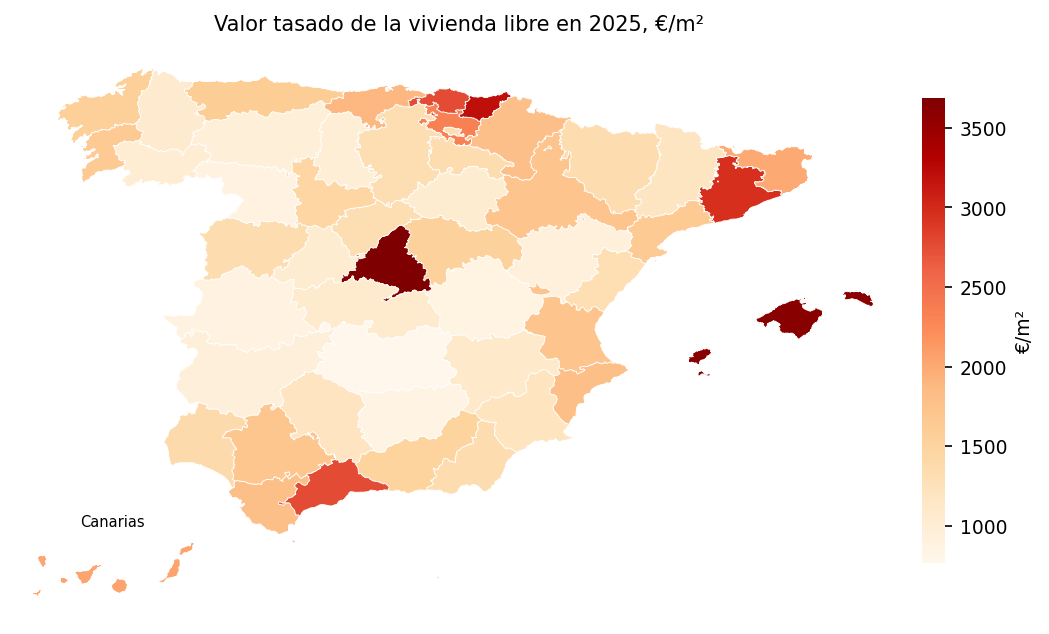

In [6]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

CANARIAS = ["35", "38"]

vmin = mapa["price_nominal_eur_m2"].min()
vmax = mapa["price_nominal_eur_m2"].max()
cmap = "OrRd"
norm = Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(8, 6))

mapa[~mapa["province_code"].isin(CANARIAS)].plot(
    ax=ax,
    column="price_nominal_eur_m2",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.4,
)

ax.set_xlim(-10.0, 4.8)
ax.set_ylim(34.6, 44.2)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Valor tasado de la vivienda libre en 2025, €/m²")

ax_can = ax.inset_axes([0.01, 0.0, 0.20, 0.18])
mapa[mapa["province_code"].isin(CANARIAS)].plot(
    ax=ax_can,
    column="price_nominal_eur_m2",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.4,
)
ax_can.set_xlim(-18.4, -13.2)
ax_can.set_ylim(27.4, 29.6)
ax_can.set_aspect("equal")
ax_can.set_axis_off()
ax_can.set_title("Canarias", fontsize=7, pad=1)

colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.025, pad=0.02
)
colorbar.set_label("€/m²")
colorbar.outline.set_visible(False)

fig.savefig(FIGURES_DIR / "01_mapa_2025.png", dpi=150, bbox_inches="tight")
plt.show()

##### 3. Tabla

In [7]:
ranking = (
    panel.loc[
        (panel["year"] == 2025)
        & (panel["kind"] == "total")
        & (panel["province_code"] != NATIONAL_CODE),
        ["province_code", "price_nominal_eur_m2"],
    ]
    .dropna(subset=["price_nominal_eur_m2"])
    .assign(name=lambda df: df["province_code"].map(PROVINCES))
    .sort_values("price_nominal_eur_m2")
    .reset_index(drop=True)
)

ranking.head(3)

# El total nacional como numero suelto: la serie de arriba es una tabla de
# 19 filas y no sirve para dibujar una linea vertical.
national_2025 = panel.loc[
    (panel["province_code"] == NATIONAL_CODE)
    & (panel["kind"] == "total")
    & (panel["year"] == 2025),
    "price_nominal_eur_m2",
].iloc[0]

print(f"Provincias en el ranking: {len(ranking)}")
print(f"España 2025: {eur(national_2025)} €/m²")


Provincias en el ranking: 52
España 2025: 2.128 €/m²


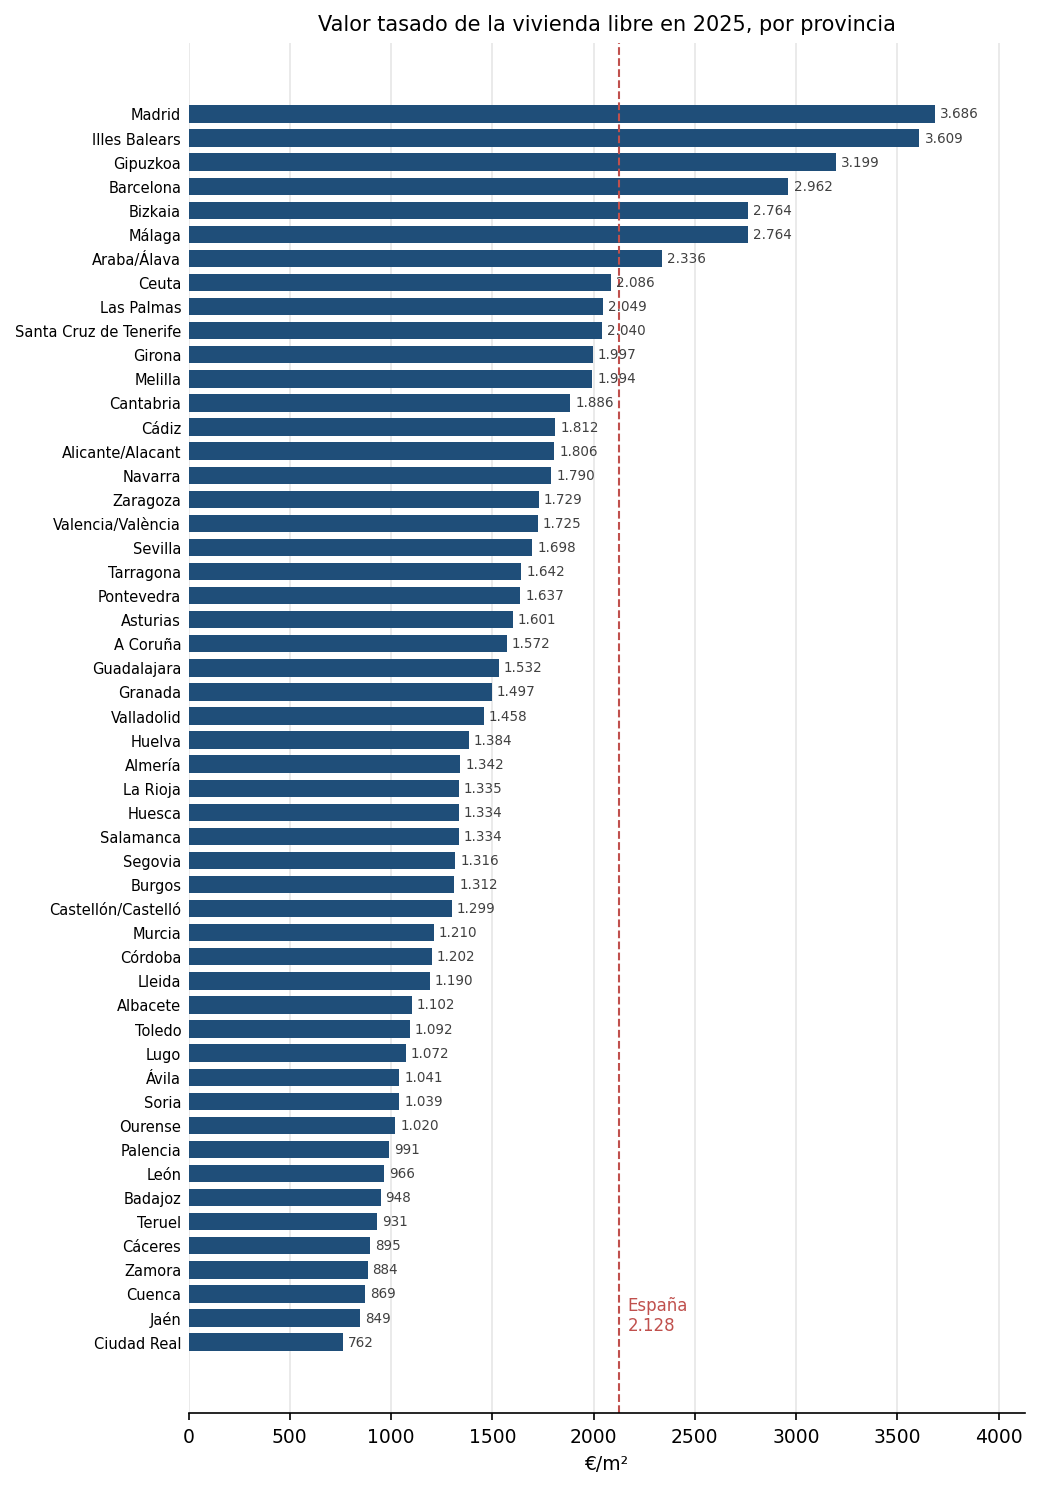

In [8]:
fig, ax = plt.subplots(figsize=(7, 10))

ax.barh(ranking["name"], ranking["price_nominal_eur_m2"], color="#1f4e79", height=0.72)

ax.axvline(national_2025, color="#c0504d", linestyle="--", linewidth=1)
ax.text(
    national_2025 + 40, 0.3, f"España\n{eur(national_2025)}",
    color="#c0504d", fontsize=8, va="bottom",
)

for y, value in enumerate(ranking["price_nominal_eur_m2"]):
    ax.text(value + 25, y, eur(value), va="center", fontsize=6.5, color="0.25")

ax.set_xlim(0, ranking["price_nominal_eur_m2"].max() * 1.12)
ax.set_xlabel("€/m²")
ax.set_title("Valor tasado de la vivienda libre en 2025, por provincia")
ax.grid(axis="x", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0, labelsize=7)
ax.spines["left"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_ranking_2025.png", dpi=150, bbox_inches="tight")
plt.show()